# Жолдағы кедергілерді анықтау жүйесін бағалау

45 тест суреті, адамның белгілері, CLAHE режимдерінің салыстырмасы. Ұяшықтарды ретімен орындаңыз.

## 1-ұяшық



In [1]:
import sys
import subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if not IN_COLAB:
    try:
        import google.colab
        IN_COLAB = True
    except ImportError:
        pass
if IN_COLAB:
    # Colab-тағы torch/torchvision сақталады.
    # Жобаның requirements.txt файлы өзгермейді.
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "ultralytics==8.4.206", "pandas", "matplotlib", "Pillow"
    ])
import csv
import io
import os
import json
import hashlib
import platform
import urllib.request
import importlib.util
import importlib.metadata
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from IPython.display import display, Markdown
plt.rcParams["font.family"] = "DejaVu Sans"
BASE_COMMIT = "f3ea5b900f9ec08ef4d823e6e9addfd270a4bc58"
CONF = 0.25
CONDITIONS = {
    "day": "Күндіз",
    "night": "Түн",
    "fog": "Тұман"
}
MODES = {
    False: "CLAHE жоқ",
    True: "CLAHE бар"
}
FILENAMES = (
    [f"day/day_p_{n:02d}.jpeg" for n in range(1, 16)]
    + [f"night/night_{n:02d}.jpeg" for n in range(4, 19)]
    + [f"fog/fog_road_{n:02d}.jpeg" for n in range(1, 16)]
)
roots = [Path.cwd(), Path.cwd().parent]
ROOT = next(
    (
        p for p in roots
        if (p / "src/alert.py").is_file()
        and (p / "data/test").is_dir()
    ),
    None
)
if ROOT is None:
    ROOT = (
        Path("/content/redflag-evaluation")
        if IN_COLAB
        else Path.cwd() / "redflag-evaluation"
    )
    def fetch(relative):
        url = (
            "https://raw.githubusercontent.com/"
            f"maratnarli/redflag/{BASE_COMMIT}/{relative}"
        )
        with urllib.request.urlopen(url, timeout=60) as response:
            data = response.read()
        target = ROOT / relative
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(data)
    with ThreadPoolExecutor(max_workers=4) as pool:
        list(pool.map(
            fetch,
            ["src/alert.py", "src/detector.py"]
            + ["data/test/" + f for f in FILENAMES]
        ))
    # Белгілер бекітілген нұсқада болса ғана жүктеу.
    # Басқа желі қатесін жасырмаймыз.
    try:
        fetch("data/test_labels.csv")
    except urllib.error.HTTPError as error:
        if error.code != 404:
            raise
paths = [
    ROOT / "data/test" / relative
    for relative in FILENAMES
]
actual = {
    p.relative_to(ROOT / "data/test").as_posix()
    for p in (ROOT / "data/test").rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
}
if actual != set(FILENAMES):
    raise ValueError(
        "Тест суреттерінің тізімі күтілетін 45 файлға сәйкес емес."
    )
for path in paths:
    with Image.open(path) as image:
        image.load()
manifest = pd.DataFrame([
    {
        "image": p.name,
        "condition": p.parent.name,
        "relative_path": p.relative_to(ROOT).as_posix()
    }
    for p in paths
])
print("Барлық 45 сурет ашылды. Жұмыс папкасы:", ROOT)
display(
    manifest.groupby("condition")
    .size()
    .rename(index=CONDITIONS)
    .rename("Сурет саны")
    .to_frame()
)


Барлық 45 сурет ашылды. Жұмыс папкасы: /content/redflag-evaluation


,Сурет саны
condition,
Күндіз,15
Тұман,15
Түн,15


## 2-ұяшық

CSV бағандары дәл image,condition,danger_gt,comment болуы керек. «Анық емес» суреттердің danger_gt мәні бос қалады. Код 37 нақты және 8 бос белгіні тексереді.

In [3]:
LABEL_PATH = ROOT / "data/test_labels.csv"
if not LABEL_PATH.exists():
    if IN_COLAB:
        from google.colab import files
        print("Қолмен белгіленген test_labels.csv файлын таңдаңыз.")
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError("Бір ғана CSV файлын жүктеңіз.")
        label_bytes = next(iter(uploaded.values()))
    else:
        entered = input(
            "test_labels.csv файлының толық жолы: "
        ).strip()
        label_bytes = Path(entered).expanduser().read_bytes()
else:
    label_bytes = LABEL_PATH.read_bytes()
def read_labels(content, expected):
    reader = csv.DictReader(
        io.StringIO(content.decode("utf-8-sig"))
    )
    fields = ["image", "condition", "danger_gt", "comment"]
    if reader.fieldnames != fields:
        raise ValueError(
            "CSV бағандары: " + ", ".join(fields)
        )
    rows = []
    for row in reader:
        if None in row or any(row[f] is None for f in fields):
            raise ValueError(
                "CSV жолындағы баған саны дұрыс емес."
            )
        value = row["danger_gt"].strip()
        if value not in ("", "0", "1"):
            raise ValueError(
                "danger_gt тек 0, 1 немесе бос болуы керек: "
                + row["image"]
            )
        rows.append({
            **row,
            "danger_gt": int(value) if value else pd.NA
        })
    frame = pd.DataFrame(rows, columns=fields)
    if frame.duplicated(["image", "condition"]).any():
        raise ValueError(
            "CSV ішінде қайталанған сурет бар."
        )
    expected_keys = set(map(
        tuple,
        expected[["image", "condition"]].to_numpy()
    ))
    found_keys = set(map(
        tuple,
        frame[["image", "condition"]].to_numpy()
    ))
    if found_keys != expected_keys:
        raise ValueError(
            "CSV суреттері сәйкес емес. "
            f"Жоқ: {expected_keys - found_keys}; "
            f"артық: {found_keys - expected_keys}"
        )
    frame["danger_gt"] = frame["danger_gt"].astype("Int64")
    return expected.merge(
        frame,
        on=["image", "condition"],
        validate="one_to_one"
    )
labels = read_labels(label_bytes, manifest)
known_count = int(labels.danger_gt.notna().sum())
unknown_count = int(labels.danger_gt.isna().sum())
print(
    f"Нақты белгі: {known_count}; "
    f"анық емес: {unknown_count}."
)
if (known_count, unknown_count) != (37, 8):
    raise ValueError(
        "Күтілетіні — 37 нақты және 8 бос белгі. "
        "Жүктелген CSV файлын тексеріңіз."
    )
# Тек тексерілген адам белгілері сақталады.
# Ешбір жауап автоматты жасалмайды.
LABEL_PATH.parent.mkdir(parents=True, exist_ok=True)
if not LABEL_PATH.exists():
    LABEL_PATH.write_bytes(label_bytes)
display(
    labels.assign(
        Жағдай=labels.condition.map(CONDITIONS)
    )
    .groupby("Жағдай")
    .agg(
        Суреттер=("image", "size"),
        Белгіленген=("danger_gt", "count")
    )
)


Қолмен белгіленген test_labels.csv файлын таңдаңыз.


Saving test_labels-2.csv to test_labels-2.csv
Нақты белгі: 37; анық емес: 8.


,Суреттер,Белгіленген
Жағдай,,
Күндіз,15,15
Түн,15,7
Тұман,15,15


## 3-ұяшық

45 суреттің әрқайсысына екі режимде болжам жасалады. Бастапқы conf=0.25 сақталады. Бұл кезең CPU-да біраз уақыт алуы мүмкін.

In [4]:
def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module
detector = load_module(
    "redflag_evaluation_detector",
    ROOT / "src/detector.py"
)
alert = load_module(
    "redflag_evaluation_alert",
    ROOT / "src/alert.py"
)
detect = detector.detect
check_frame = alert.check_frame
prediction_rows, detail_rows = [], []
frame_results = {}
for index, path in enumerate(paths, 1):
    frame = cv2.imread(str(path))
    if frame is None:
        raise ValueError(
            "Сурет оқылмады: " + str(path)
        )
    for use_clahe in (False, True):
        result = check_frame(
            detect(
                frame,
                conf=CONF,
                use_clahe=use_clahe
            ),
            frame.shape
        )
        frame_results[
            (path.name, path.parent.name, use_clahe)
        ] = result
        threats = [
            item["label"]
            for item in result["items"]
            if item["status"] == "threat"
        ]
        prediction_rows.append({
            "image": path.name,
            "condition": path.parent.name,
            "use_clahe": use_clahe,
            "danger_pred": int(result["danger"]),
            "threats": " ".join(threats),
            "detection_count": len(result["items"])
        })
        for item in result["items"]:
            x1, y1, x2, y2 = item["box"]
            detail_rows.append({
                "image": path.name,
                "condition": path.parent.name,
                "use_clahe": use_clahe,
                "label": item["label"],
                "confidence": item["conf"],
                "x1": x1,
                "y1": y1,
                "x2": x2,
                "y2": y2,
                "status": item["status"],
                "reason": item["reason"]
            })
    print(f"{index}/45: {path.name} — дайын")
predictions = pd.DataFrame(prediction_rows)
if (
    len(predictions) != 90
    or predictions.duplicated(
        ["image", "condition", "use_clahe"]
    ).any()
):
    raise ValueError(
        "90 бірегей болжам қажет."
    )
joined = predictions.merge(
    labels,
    on=["image", "condition"],
    validate="many_to_one"
)
# Бос белгілерді метрикаларға қоспаймыз.
scored = joined[joined.danger_gt.notna()].copy()
scored["danger_gt"] = scored.danger_gt.astype(int)
assert len(scored) == 74


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
1/45: day_p_01.jpeg — дайын
2/45: day_p_02.jpeg — дайын
3/45: day_p_03.jpeg — дайын
4/45: day_p_04.jpeg — дайын
5/45: day_p_05.jpeg — дайын
6/45: day_p_06.jpeg — дайын
7/45: day_p_07.jpeg — дайын
8/45: day_p_08.jpeg — дайын
9/45: day_p_09.jpeg — дайын
10/45: day_p_10.jpeg — дайын
11/45: day_p_11.jpeg — дайын
12/45: day_p_12.jpeg — дайын
13/45: day_p_13.jpeg — дайын
14/45: day_p_14.jpeg — дайын
15/45: day_p_15.jpeg — дайын
16/45: night_04.jpeg — дайын
17/45: night_05.jpeg — дайын
18/45: night_06.jpeg — дайын
19/45: night_07.jpeg — дайын
20/45: night_08.jpeg — дайын
21/45: night_09.jpeg — дайын
22/45: night_10.jpeg — дайын
23/45: night_11.jpeg — дайын
24/45: night_12.jpeg — дайын
25/45: night_13.jpeg 

## 4-ұяшық

Бұл — кадр бойынша ескерту сапасы. Объектілердің mAP көрсеткіші есептелмейді. Метрика бөлгіші нөл болса, мәні NaN болады.

In [5]:
def metric_row(frame):
    gt = frame.danger_gt.astype(int)
    pred = frame.danger_pred.astype(int)
    tp = int(((gt == 1) & (pred == 1)).sum())
    tn = int(((gt == 0) & (pred == 0)).sum())
    fp = int(((gt == 0) & (pred == 1)).sum())
    fn = int(((gt == 1) & (pred == 0)).sum())
    divide = lambda numerator, denominator: (
        numerator / denominator
        if denominator
        else float("nan")
    )
    return {
        "n": len(frame),
        "positive": int((gt == 1).sum()),
        "negative": int((gt == 0).sum()),
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "precision": divide(tp, tp + fp),
        "recall": divide(tp, tp + fn),
        "f1": divide(2 * tp, 2 * tp + fp + fn),
        "accuracy": divide(tp + tn, len(frame))
    }
scored["outcome"] = [
    "TP" if g == 1 and p == 1
    else "TN" if g == 0 and p == 0
    else "FP" if p == 1
    else "FN"
    for g, p in zip(
        scored.danger_gt,
        scored.danger_pred
    )
]
metric_rows = []
for mode in (False, True):
    for condition in ("all", "day", "night", "fog"):
        subset = scored[scored.use_clahe == mode]
        if condition != "all":
            subset = subset[
                subset.condition == condition
            ]
        metric_rows.append({
            "condition": condition,
            "use_clahe": mode,
            **metric_row(subset)
        })
metrics = pd.DataFrame(metric_rows)
HEADERS = {
    "image": "Сурет",
    "condition": "Жағдай",
    "use_clahe": "Режим",
    "danger_gt": "Адам белгісі",
    "danger_pred": "Жүйе жауабы",
    "comment": "Түсініктеме",
    "n": "Бағаланған кадр",
    "positive": "Қауіпті",
    "negative": "Қауіпсіз",
    "precision": "Дәлдік (Precision)",
    "recall": "Толықтық (Recall)",
    "f1": "F1 көрсеткіші",
    "accuracy": "Дұрыс жауап үлесі (Accuracy)",
    "outcome": "Нәтиже түрі",
    "threats": "Табылған қауіп кластары",
    "TP": "TP — дұрыс ескерту",
    "TN": "TN — дұрыс үнсіз қалу",
    "FP": "FP — жалған ескерту",
    "FN": "FN — қауіпті өткізіп алу"
}
def kazakh_table(frame):
    result = frame.copy()
    if "condition" in result:
        result["condition"] = result.condition.map({
            **CONDITIONS,
            "all": "Барлығы"
        })
    if "use_clahe" in result:
        result["use_clahe"] = result.use_clahe.map(MODES)
    return result.rename(columns=HEADERS)
print(
    "Негізгі бағалау: тек 37 нақты белгі, "
    "әр режимге бөлек."
)
display(kazakh_table(metrics).round(3))
unknown = labels[labels.danger_gt.isna()].copy()
unknown_table = unknown[
    ["image", "condition", "danger_gt", "comment"]
].merge(
    predictions.pivot(
        index=["image", "condition"],
        columns="use_clahe",
        values="danger_pred"
    )
    .rename(columns={
        False: "CLAHE жоқ: жүйе жауабы",
        True: "CLAHE бар: жүйе жауабы"
    })
    .reset_index(),
    on=["image", "condition"],
    validate="one_to_one"
)
print(
    "Негізгі метрикалардан шығарылған 8 сурет "
    "(жүйе жауаптары эталон емес):"
)
display(kazakh_table(unknown_table))
paired = scored.pivot(
    index=["image", "condition", "danger_gt"],
    columns="use_clahe",
    values="danger_pred"
)
assert len(paired) == 37 and paired.notna().all().all()
paired = paired.rename(columns={
    False: "plain_pred",
    True: "clahe_pred"
}).reset_index()
paired["plain_correct"] = (
    paired.plain_pred == paired.danger_gt
)
paired["clahe_correct"] = (
    paired.clahe_pred == paired.danger_gt
)
print(
    "CLAHE түзеткен кадр:",
    int((
        ~paired.plain_correct
        & paired.clahe_correct
    ).sum())
)
print(
    "CLAHE қате қылған кадр:",
    int((
        paired.plain_correct
        & ~paired.clahe_correct
    ).sum())
)


Негізгі бағалау: тек 37 нақты белгі, әр режимге бөлек.


,Жағдай,Режим,Бағаланған кадр,Қауіпті,Қауіпсіз,TP — дұрыс ескерту,TN — дұрыс үнсіз қалу,FP — жалған ескерту,FN — қауіпті өткізіп алу,Дәлдік (Precision),Толықтық (Recall),F1 көрсеткіші,Дұрыс жауап үлесі (Accuracy)
0,Барлығы,CLAHE жоқ,37,10,27,8,21,6,2,0.571,0.800,0.667,0.784
1,Күндіз,CLAHE жоқ,15,3,12,3,6,6,0,0.333,1.000,0.500,0.600
2,Түн,CLAHE жоқ,7,0,7,0,7,0,0,NaN,NaN,NaN,1.000
3,Тұман,CLAHE жоқ,15,7,8,5,8,0,2,1.000,0.714,0.833,0.867
4,Барлығы,CLAHE бар,37,10,27,8,21,6,2,0.571,0.800,0.667,0.784
5,Күндіз,CLAHE бар,15,3,12,3,6,6,0,0.333,1.000,0.500,0.600
6,Түн,CLAHE бар,7,0,7,0,7,0,0,NaN,NaN,NaN,1.000
7,Тұман,CLAHE бар,15,7,8,5,8,0,2,1.000,0.714,0.833,0.867


Негізгі метрикалардан шығарылған 8 сурет (жүйе жауаптары эталон емес):


,Сурет,Жағдай,Адам белгісі,Түсініктеме,CLAHE жоқ: жүйе жауабы,CLAHE бар: жүйе жауабы
0,night_11.jpeg,Түн,<NA>,[Анық емес] Түнгі уақытта көлік фаралары қатты...,0,0
1,night_12.jpeg,Түн,<NA>,[Анық емес] Жақын орналасқан автомобильдің фар...,0,0
2,night_13.jpeg,Түн,<NA>,[Анық емес] Жақын орналасқан автомобильдің фар...,0,0
3,night_14.jpeg,Түн,<NA>,[Анық емес] Жақын орналасқан автомобильдің фар...,0,0
4,night_15.jpeg,Түн,<NA>,[Анық емес] Жақын орналасқан автомобильдің фар...,0,0
5,night_16.jpeg,Түн,<NA>,[Анық емес] Жақын орналасқан автомобильдің фар...,0,0
6,night_17.jpeg,Түн,<NA>,[Анық емес] Жақын орналасқан автомобильдің фар...,0,0
7,night_18.jpeg,Түн,<NA>,[Анық емес] Қарлы жолда бірнеше автомобиль бар...,0,0


CLAHE түзеткен кадр: 0
CLAHE қате қылған кадр: 0


## 5-ұяшық

Әр прогон үшін жаңа results/evaluation/… папкасы жасалады.

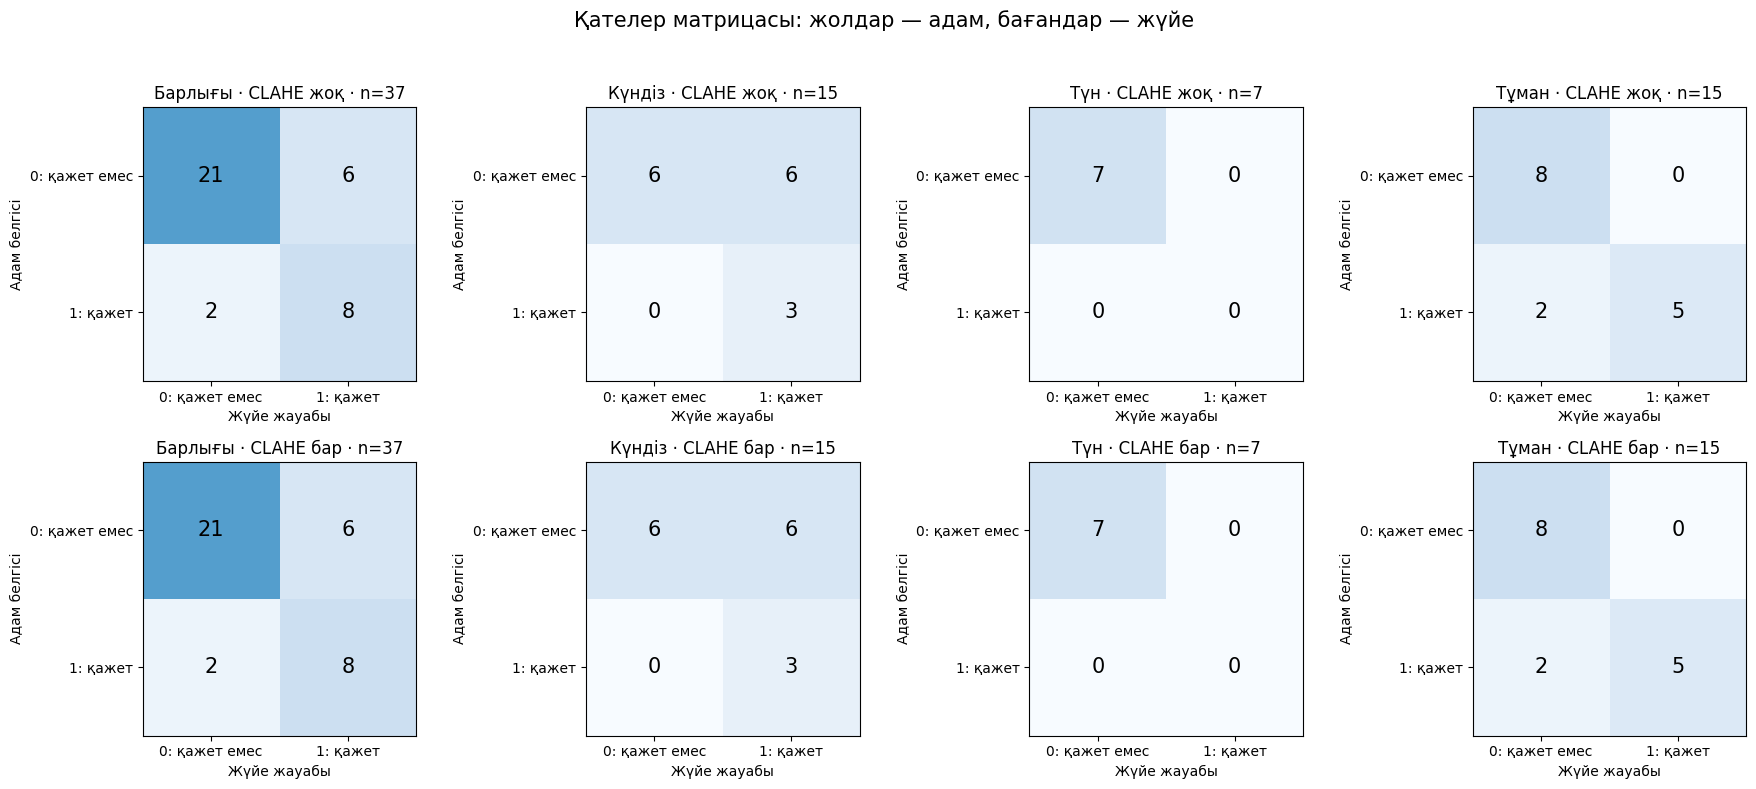

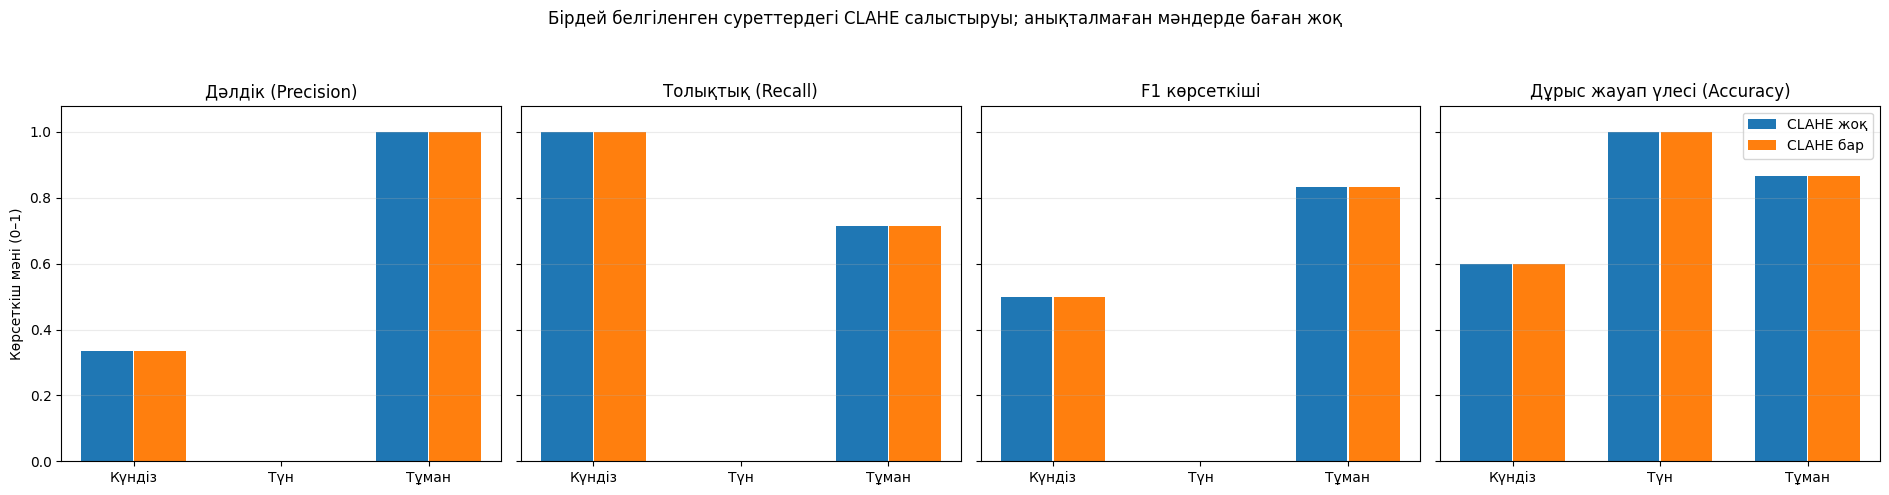

CSV және графиктер сақталды: /content/redflag-evaluation/results/evaluation/20261109T130015258090Z


In [6]:
# Бұрынғы tuning нәтижелері қайта жазылмайды.
run_id = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S%fZ"
)
OUT = ROOT / "results" / "evaluation" / run_id
OUT.mkdir(parents=True, exist_ok=False)
def save_csv(frame, name):
    frame.to_csv(
        OUT / name,
        index=False,
        encoding="utf-8-sig",
        na_rep=""
    )
save_csv(predictions, "test_predictions.csv")
save_csv(joined, "comparison_all.csv")
save_csv(scored, "scored_predictions.csv")
save_csv(unknown_table, "uncertain_images.csv")
save_csv(metrics, "metrics.csv")
save_csv(kazakh_table(metrics), "metrics_kz.csv")
save_csv(paired, "paired_comparison.csv")
save_csv(
    labels[["image", "condition", "danger_gt", "comment"]],
    "test_labels_used.csv"
)
save_csv(
    pd.DataFrame(detail_rows, columns=[
        "image", "condition", "use_clahe",
        "label", "confidence",
        "x1", "y1", "x2", "y2", "status", "reason"
    ]),
    "detections.csv"
)
confusion_rows = []
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for row_index, mode in enumerate((False, True)):
    for column_index, condition in enumerate(
        ("all", "day", "night", "fog")
    ):
        row = metrics[
            (metrics.use_clahe == mode)
            & (metrics.condition == condition)
        ].iloc[0]
        matrix = np.array([
            [row.TN, row.FP],
            [row.FN, row.TP]
        ], dtype=int)
        ax = axes[row_index, column_index]
        ax.imshow(
            matrix,
            cmap="Blues",
            vmin=0,
            vmax=max(int(metrics.n.max()), 1)
        )
        for y in range(2):
            for x in range(2):
                ax.text(
                    x, y, str(matrix[y, x]),
                    ha="center",
                    va="center",
                    fontsize=15
                )
                confusion_rows.append({
                    "condition": condition,
                    "use_clahe": mode,
                    "danger_gt": y,
                    "danger_pred": x,
                    "count": int(matrix[y, x])
                })
        ax.set(
            xticks=[0, 1],
            yticks=[0, 1],
            xticklabels=["0: қажет емес", "1: қажет"],
            yticklabels=["0: қажет емес", "1: қажет"],
            xlabel="Жүйе жауабы",
            ylabel="Адам белгісі",
            title=(
                f"{CONDITIONS.get(condition, 'Барлығы')} · "
                f"{MODES[mode]} · n={int(row.n)}"
            )
        )
fig.suptitle(
    "Қателер матрицасы: жолдар — адам, бағандар — жүйе",
    fontsize=15
)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(
    OUT / "confusion_matrices.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()
save_csv(
    pd.DataFrame(confusion_rows),
    "confusion_matrices.csv"
)
fig, axes = plt.subplots(
    1, 4, figsize=(19, 5), sharey=True
)
for ax, metric in zip(
    axes,
    ["precision", "recall", "f1", "accuracy"]
):
    for offset, mode in [
        (-0.18, False),
        (0.18, True)
    ]:
        selected = (
            metrics[metrics.use_clahe == mode]
            .set_index("condition")
            .loc[["day", "night", "fog"]]
        )
        ax.bar(
            np.arange(3) + offset,
            selected[metric],
            width=0.35,
            label=MODES[mode]
        )
    ax.set(
        xticks=np.arange(3),
        xticklabels=list(CONDITIONS.values()),
        ylim=(0, 1.08),
        title=HEADERS[metric]
    )
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Көрсеткіш мәні (0–1)")
axes[-1].legend()
fig.suptitle(
    "Бірдей белгіленген суреттердегі CLAHE салыстыруы; "
    "анықталмаған мәндерде баған жоқ"
)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(
    OUT / "metrics_by_condition.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()
print("CSV және графиктер сақталды:", OUT)


## 6-ұяшық

Қате табылмаса, код оны ашық айтады. Жоқ қате ойдан жасалмайды.

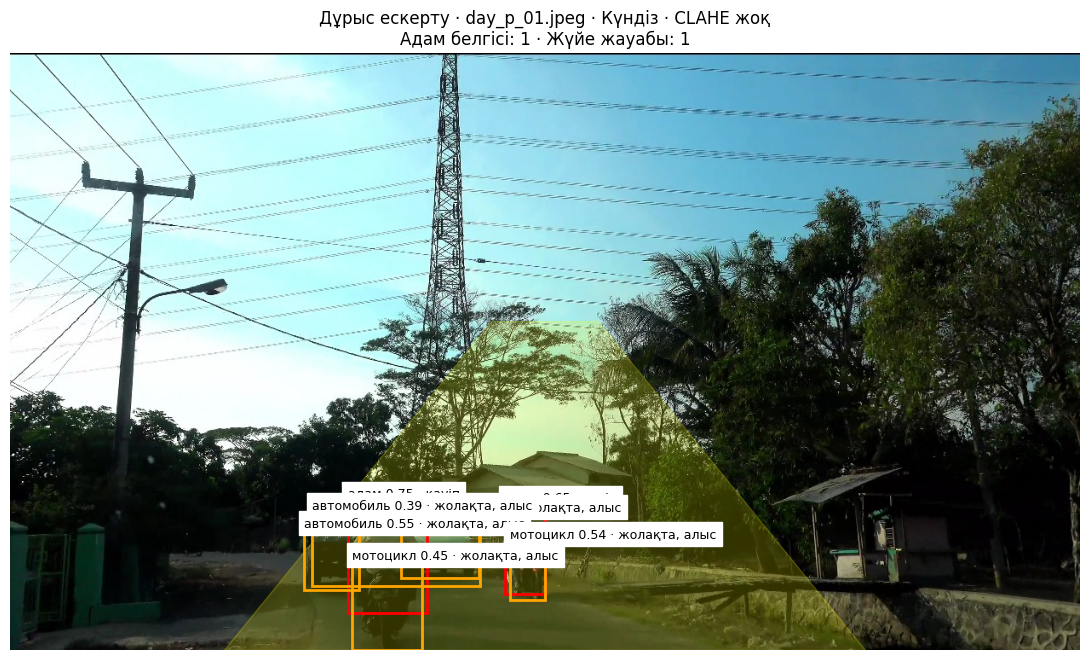

Адам түсініктемесі: Жолдың орталық бөлігінде жақын орналасқан мотоцикл жүргізушісі бар.


,Нысан,Сенімділік,Күйі,Себебі
0,адам,0.748,қауіп,жолақта адам/жануар
1,адам,0.647,қауіп,жолақта адам/жануар
2,автомобиль,0.638,"жолақта, алыс","жолақта, бірақ алыс"
3,автомобиль,0.551,"жолақта, алыс","жолақта, бірақ алыс"
4,мотоцикл,0.538,"жолақта, алыс","жолақта, бірақ алыс"
5,мотоцикл,0.447,"жолақта, алыс","жолақта, бірақ алыс"
6,автомобиль,0.386,"жолақта, алыс","жолақта, бірақ алыс"


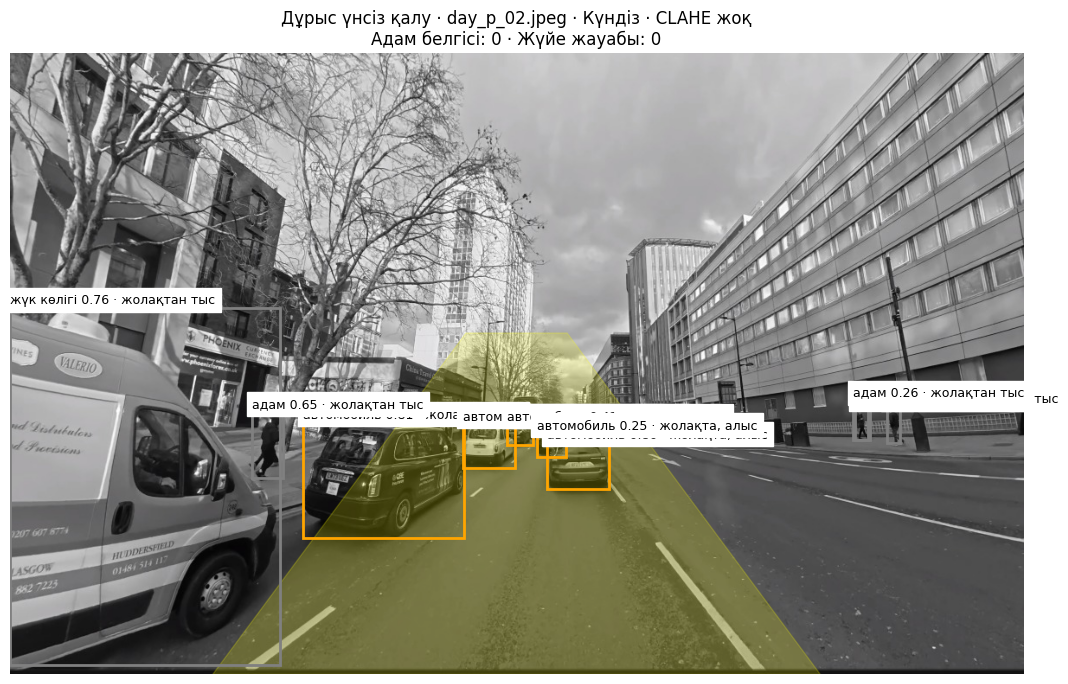

Адам түсініктемесі: Орталық аймақтағы көлік алыста орналасқан, ал жақын көліктер қауіпті аймақтан тыс. Ескерту шарттары орындалмайды.


,Нысан,Сенімділік,Күйі,Себебі
0,автомобиль,0.810,"жолақта, алыс","жолақта, бірақ алыс"
1,автомобиль,0.796,"жолақта, алыс","жолақта, бірақ алыс"
2,жүк көлігі,0.755,жолақтан тыс,жолақтан тыс
3,адам,0.649,жолақтан тыс,жолақтан тыс
4,автомобиль,0.626,"жолақта, алыс","жолақта, бірақ алыс"
5,адам,0.483,жолақтан тыс,жолақтан тыс
6,адам,0.445,жолақтан тыс,жолақтан тыс
7,автомобиль,0.405,"жолақта, алыс","жолақта, бірақ алыс"
8,адам,0.263,жолақтан тыс,жолақтан тыс
9,автомобиль,0.252,"жолақта, алыс","жолақта, бірақ алыс"


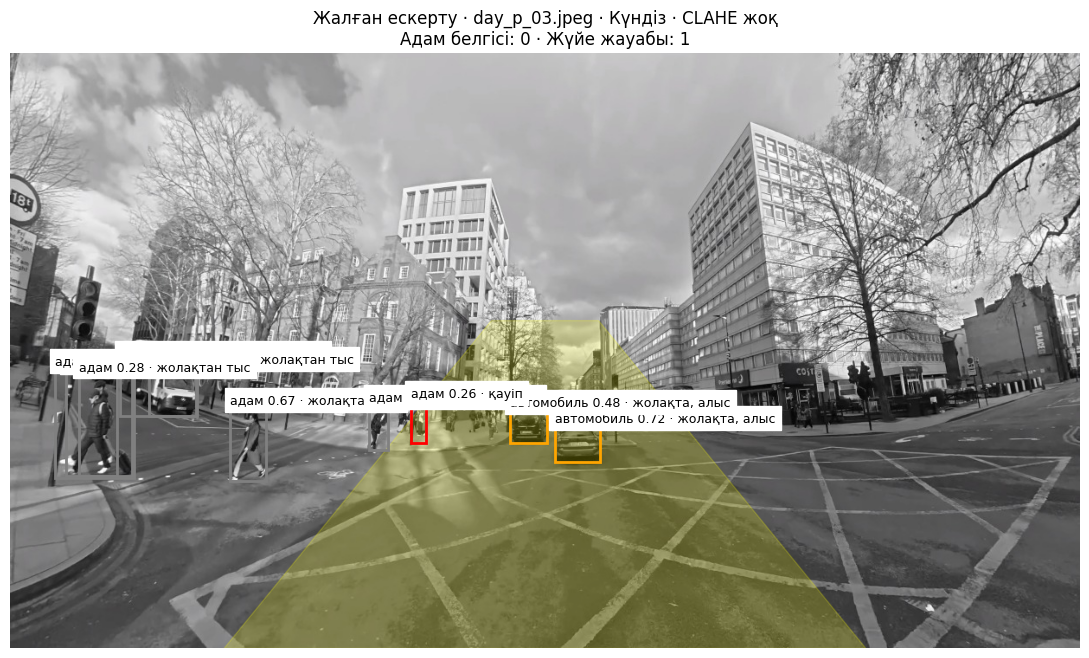

Адам түсініктемесі: Ешқандай кедергі жоқ


,Нысан,Сенімділік,Күйі,Себебі
0,автомобиль,0.722,"жолақта, алыс","жолақта, бірақ алыс"
1,адам,0.674,жолақтан тыс,жолақтан тыс
2,адам,0.495,жолақтан тыс,жолақтан тыс
3,адам,0.486,жолақтан тыс,жолақтан тыс
4,автомобиль,0.482,"жолақта, алыс","жолақта, бірақ алыс"
5,жүк көлігі,0.368,жолақтан тыс,жолақтан тыс
6,адам,0.364,жолақтан тыс,жолақтан тыс
7,жүк көлігі,0.357,жолақтан тыс,жолақтан тыс
8,адам,0.282,жолақтан тыс,жолақтан тыс
9,адам,0.263,қауіп,жолақта адам/жануар


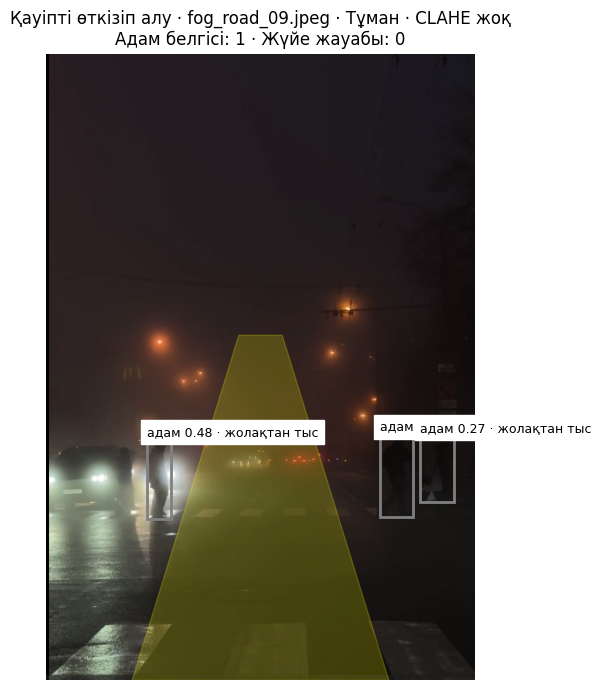

Адам түсініктемесі: Тұманды жағдайда жаяу жүргінші жолдың қауіпті аймағында орналасқан. Соқтығысу қаупін ескерту қажет.


,Нысан,Сенімділік,Күйі,Себебі
0,адам,0.685,жолақтан тыс,жолақтан тыс
1,адам,0.481,жолақтан тыс,жолақтан тыс
2,адам,0.272,жолақтан тыс,жолақтан тыс


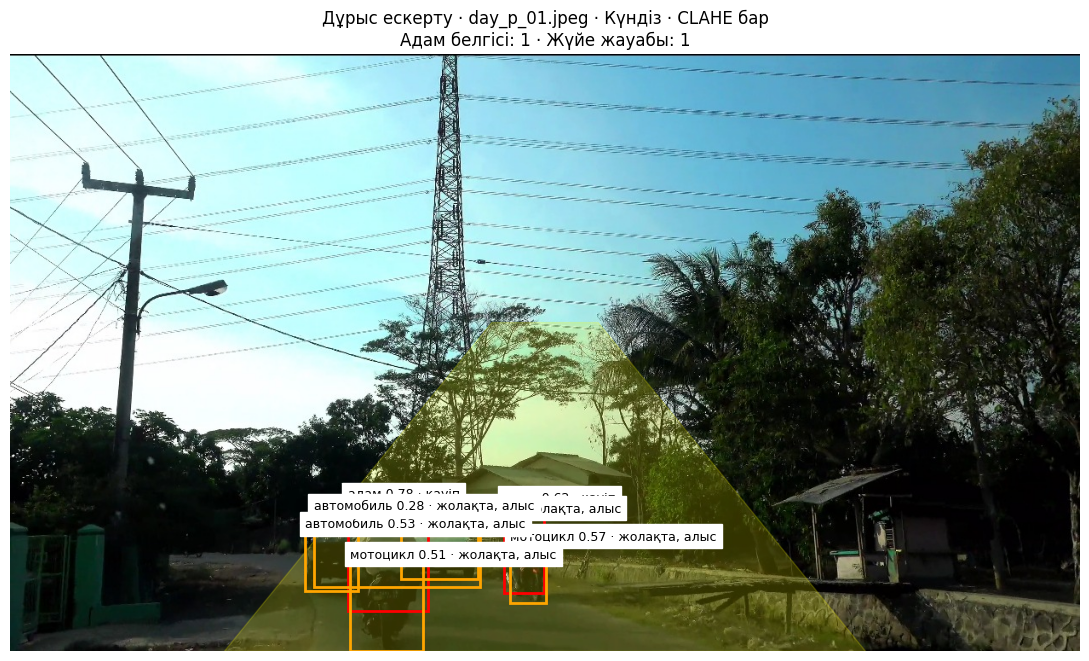

Адам түсініктемесі: Жолдың орталық бөлігінде жақын орналасқан мотоцикл жүргізушісі бар.


,Нысан,Сенімділік,Күйі,Себебі
0,адам,0.783,қауіп,жолақта адам/жануар
1,адам,0.625,қауіп,жолақта адам/жануар
2,автомобиль,0.625,"жолақта, алыс","жолақта, бірақ алыс"
3,мотоцикл,0.567,"жолақта, алыс","жолақта, бірақ алыс"
4,автомобиль,0.533,"жолақта, алыс","жолақта, бірақ алыс"
5,мотоцикл,0.513,"жолақта, алыс","жолақта, бірақ алыс"
6,автомобиль,0.284,"жолақта, алыс","жолақта, бірақ алыс"


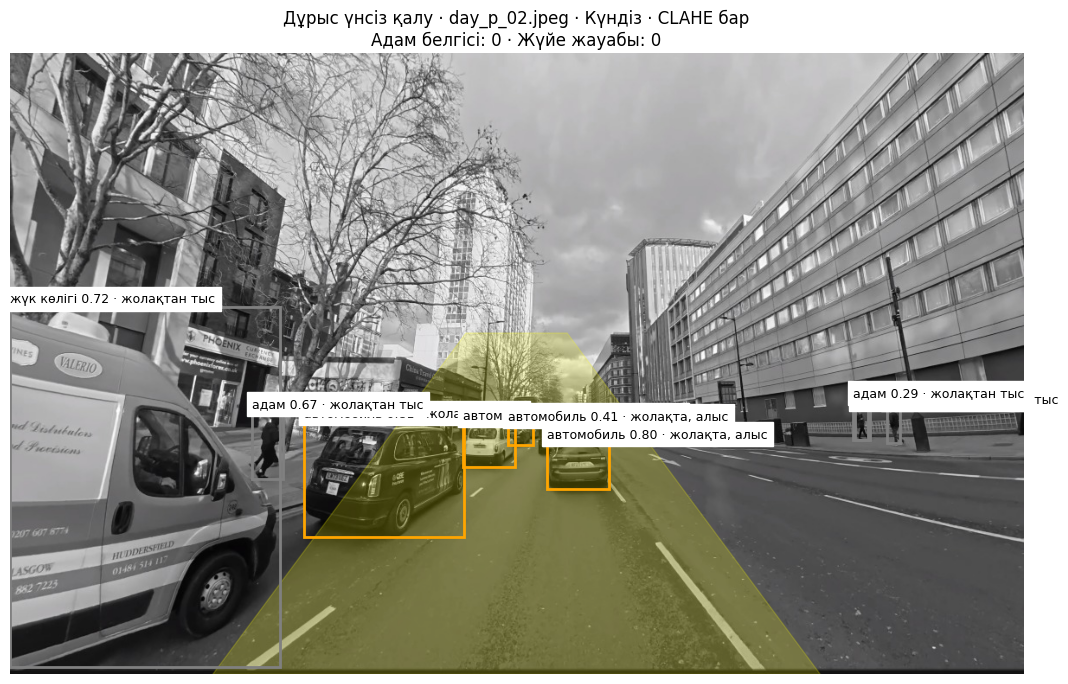

Адам түсініктемесі: Орталық аймақтағы көлік алыста орналасқан, ал жақын көліктер қауіпті аймақтан тыс. Ескерту шарттары орындалмайды.


,Нысан,Сенімділік,Күйі,Себебі
0,автомобиль,0.809,"жолақта, алыс","жолақта, бірақ алыс"
1,автомобиль,0.803,"жолақта, алыс","жолақта, бірақ алыс"
2,жүк көлігі,0.723,жолақтан тыс,жолақтан тыс
3,адам,0.669,жолақтан тыс,жолақтан тыс
4,автомобиль,0.535,"жолақта, алыс","жолақта, бірақ алыс"
5,адам,0.483,жолақтан тыс,жолақтан тыс
6,адам,0.478,жолақтан тыс,жолақтан тыс
7,автомобиль,0.407,"жолақта, алыс","жолақта, бірақ алыс"
8,адам,0.286,жолақтан тыс,жолақтан тыс


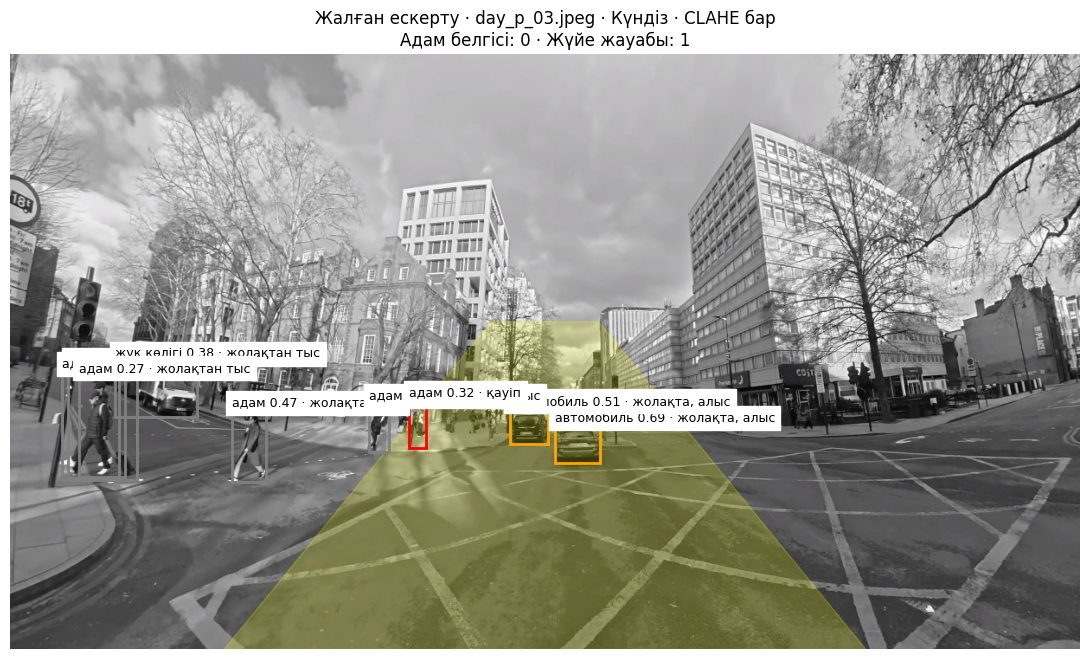

Адам түсініктемесі: Ешқандай кедергі жоқ


,Нысан,Сенімділік,Күйі,Себебі
0,автомобиль,0.694,"жолақта, алыс","жолақта, бірақ алыс"
1,адам,0.534,жолақтан тыс,жолақтан тыс
2,автомобиль,0.512,"жолақта, алыс","жолақта, бірақ алыс"
3,адам,0.475,жолақтан тыс,жолақтан тыс
4,адам,0.473,жолақтан тыс,жолақтан тыс
5,адам,0.465,жолақтан тыс,жолақтан тыс
6,жүк көлігі,0.384,жолақтан тыс,жолақтан тыс
7,адам,0.316,қауіп,жолақта адам/жануар
8,адам,0.273,жолақтан тыс,жолақтан тыс


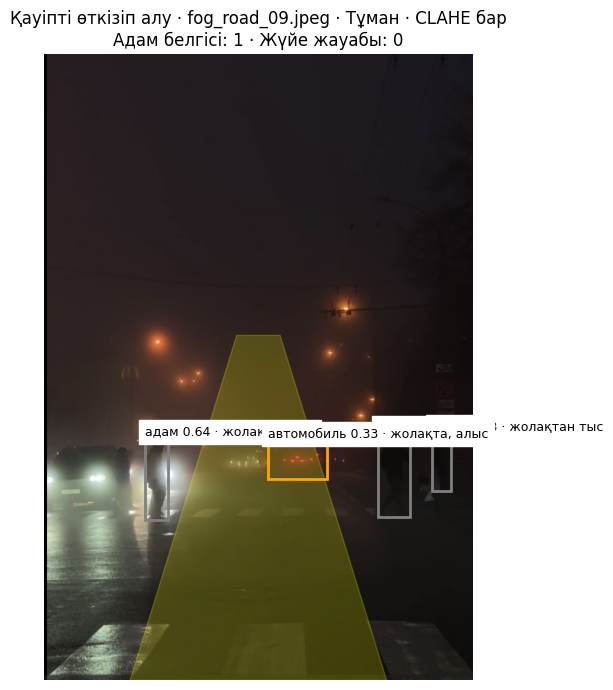

Адам түсініктемесі: Тұманды жағдайда жаяу жүргінші жолдың қауіпті аймағында орналасқан. Соқтығысу қаупін ескерту қажет.


,Нысан,Сенімділік,Күйі,Себебі
0,адам,0.757,жолақтан тыс,жолақтан тыс
1,адам,0.636,жолақтан тыс,жолақтан тыс
2,адам,0.334,жолақтан тыс,жолақтан тыс
3,автомобиль,0.329,"жолақта, алыс","жолақта, бірақ алыс"


Нақты қате мысалы: төмендегі жауап адамның белгісімен сәйкес емес.


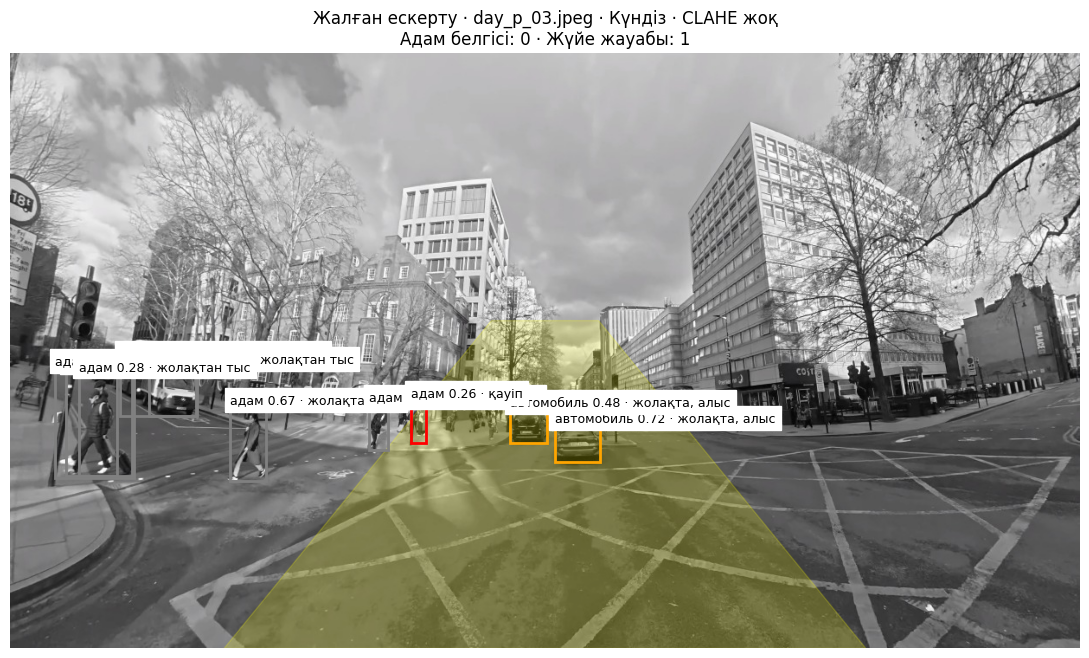

Адам түсініктемесі: Ешқандай кедергі жоқ


,Нысан,Сенімділік,Күйі,Себебі
0,автомобиль,0.722,"жолақта, алыс","жолақта, бірақ алыс"
1,адам,0.674,жолақтан тыс,жолақтан тыс
2,адам,0.495,жолақтан тыс,жолақтан тыс
3,адам,0.486,жолақтан тыс,жолақтан тыс
4,автомобиль,0.482,"жолақта, алыс","жолақта, бірақ алыс"
5,жүк көлігі,0.368,жолақтан тыс,жолақтан тыс
6,адам,0.364,жолақтан тыс,жолақтан тыс
7,жүк көлігі,0.357,жолақтан тыс,жолақтан тыс
8,адам,0.282,жолақтан тыс,жолақтан тыс
9,адам,0.263,қауіп,жолақта адам/жануар


,Сурет,Жағдай,Режим,Адам белгісі,Жүйе жауабы,Нәтиже түрі,Түсініктеме
4,day_p_03.jpeg,Күндіз,CLAHE жоқ,0,1,FP,Ешқандай кедергі жоқ
5,day_p_03.jpeg,Күндіз,CLAHE бар,0,1,FP,Ешқандай кедергі жоқ
6,day_p_04.jpeg,Күндіз,CLAHE жоқ,0,1,FP,Жақын мотоцикл қауіпті аймақтан тыс орналасқан...
7,day_p_04.jpeg,Күндіз,CLAHE бар,0,1,FP,Жақын мотоцикл қауіпті аймақтан тыс орналасқан...
10,day_p_06.jpeg,Күндіз,CLAHE жоқ,0,1,FP,"Жолдың ортасында мотоцикл бар, бірақ оның өлше..."
11,day_p_06.jpeg,Күндіз,CLAHE бар,0,1,FP,"Жолдың ортасында мотоцикл бар, бірақ оның өлше..."
14,day_p_08.jpeg,Күндіз,CLAHE жоқ,0,1,FP,"Кедергі жоқ, жүргізуші жолы ашық"
15,day_p_08.jpeg,Күндіз,CLAHE бар,0,1,FP,"Кедергі жоқ, жүргізуші жолы ашық"
16,day_p_09.jpeg,Күндіз,CLAHE жоқ,0,1,FP,Жол ашық
17,day_p_09.jpeg,Күндіз,CLAHE бар,0,1,FP,Жол ашық


Қате себебін кадр мен рамкаларды қарап талдаңыз: нысанды өткізіп алу, қате класс, аймақ немесе капот сүзгісі болуы мүмкін. Себеп автоматты түрде дәлелденбейді; тестке қарап параметрлерді өзгертпеңіз.


In [7]:
CLASS_NAMES = {
    "person": "адам",
    "bicycle": "велосипед",
    "car": "автомобиль",
    "motorcycle": "мотоцикл",
    "bus": "автобус",
    "truck": "жүк көлігі",
    "dog": "ит",
    "horse": "жылқы",
    "sheep": "қой",
    "cow": "сиыр"
}
STATUS_NAMES = {
    "threat": "қауіп",
    "in_lane": "жолақта, алыс",
    "outside": "жолақтан тыс",
    "hood": "капот"
}
OUTCOME_NAMES = {
    "TP": "Дұрыс ескерту",
    "TN": "Дұрыс үнсіз қалу",
    "FP": "Жалған ескерту",
    "FN": "Қауіпті өткізіп алу"
}
def show_example(row, filename):
    frame = cv2.imread(str(ROOT / row.relative_path))
    result = frame_results[
        (row.image, row.condition, bool(row.use_clahe))
    ]
    fig, ax = plt.subplots(figsize=(11, 7))
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    polygon = alert.lane_polygon(frame.shape)
    ax.add_patch(plt.Polygon(
        polygon,
        closed=True,
        facecolor="yellow",
        edgecolor="yellow",
        alpha=0.2
    ))
    colors = {
        "threat": "red",
        "in_lane": "orange",
        "outside": "gray",
        "hood": "gray"
    }
    for item in result["items"]:
        x1, y1, x2, y2 = item["box"]
        color = colors[item["status"]]
        ax.add_patch(plt.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor=color,
            linewidth=2
        ))
        text = (
            f"{CLASS_NAMES.get(item['label'], item['label'])} "
            f"{item['conf']:.2f} · "
            f"{STATUS_NAMES[item['status']]}"
        )
        ax.text(
            x1,
            max(y1 - 5, 10),
            text,
            fontsize=9,
            color="black",
            backgroundcolor="white"
        )
    ax.set_title(
        f"{OUTCOME_NAMES[row.outcome]} · {row.image} · "
        f"{CONDITIONS[row.condition]} · "
        f"{MODES[bool(row.use_clahe)]}\n"
        f"Адам белгісі: {int(row.danger_gt)} · "
        f"Жүйе жауабы: {row.danger_pred}"
    )
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(
        OUT / filename,
        dpi=140,
        bbox_inches="tight"
    )
    plt.show()
    print(
        "Адам түсініктемесі:",
        row.comment or "Жоқ"
    )
    explanations = [
        {
            "Нысан": CLASS_NAMES.get(
                i["label"], i["label"]
            ),
            "Сенімділік": round(i["conf"], 3),
            "Күйі": STATUS_NAMES[i["status"]],
            "Себебі": i["reason"]
        }
        for i in result["items"]
    ]
    if explanations:
        display(pd.DataFrame(explanations))
    else:
        print("Модель мақсатты нысан таппады.")
example_rows = []
for mode in (False, True):
    for outcome in ("TP", "TN", "FP", "FN"):
        subset = scored[
            (scored.use_clahe == mode)
            & (scored.outcome == outcome)
        ]
        if subset.empty:
            print(
                f"{MODES[mode]}: "
                f"{OUTCOME_NAMES[outcome]} мысалы жоқ."
            )
        else:
            row = subset.iloc[0]
            example_rows.append(row.to_dict())
            show_example(
                row,
                f"example_{int(mode)}_{outcome}.png"
            )
errors = scored[
    scored.outcome.isin(["FP", "FN"])
].copy()
save_csv(errors, "errors.csv")
save_csv(
    pd.DataFrame(example_rows),
    "examples.csv"
)
if errors.empty:
    print(
        "37 нақты белгіде екі режимде де FP/FN табылмады. "
        "Қате мысалын жасауға негіз жоқ."
    )
else:
    print(
        "Нақты қате мысалы: төмендегі жауап "
        "адамның белгісімен сәйкес емес."
    )
    show_example(
        errors.iloc[0],
        "error_case.png"
    )
    display(kazakh_table(
        errors[[
            "image",
            "condition",
            "use_clahe",
            "danger_gt",
            "danger_pred",
            "outcome",
            "comment"
        ]]
    ))
    print(
        "Қате себебін кадр мен рамкаларды қарап талдаңыз: "
        "нысанды өткізіп алу, қате класс, аймақ немесе "
        "капот сүзгісі болуы мүмкін. "
        "Себеп автоматты түрде дәлелденбейді; "
        "тестке қарап параметрлерді өзгертпеңіз."
    )


## 7-ұяшық

Кітапхана нұсқалары, кодтың, суреттердің және салмақтардың SHA-256 мәндері сақталады.

In [8]:
def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(
            lambda: stream.read(1024 * 1024),
            b""
        ):
            digest.update(block)
    return digest.hexdigest()
packages = {}
for package in [
    "ultralytics",
    "opencv-python",
    "numpy",
    "pandas",
    "torch",
    "torchvision",
    "matplotlib"
]:
    try:
        packages[package] = (
            importlib.metadata.version(package)
        )
    except importlib.metadata.PackageNotFoundError:
        packages[package] = "Орнатылмаған"
metadata = {
    "run_id": run_id,
    "source_snapshot_for_download": BASE_COMMIT,
    "python": platform.python_version(),
    "packages": packages,
    "conf": CONF,
    "images": 45,
    "labeled": known_count,
    "excluded": unknown_count,
    "labels_sha256": hashlib.sha256(
        label_bytes
    ).hexdigest(),
    "source_sha256": {
        p: sha256(ROOT / p)
        for p in [
            "src/alert.py",
            "src/detector.py"
        ]
    },
    "weights_sha256": (
        sha256(ROOT / "yolov8n.pt")
        if (ROOT / "yolov8n.pt").exists()
        else None
    ),
    "note": (
        "Жергілікті іске қосуда код нұсқасын "
        "source_sha256 сипаттайды; жүктеу нұсқасы "
        "жергілікті Git HEAD дегенді білдірмейді."
    )
}
(OUT / "run_metadata.json").write_text(
    json.dumps(
        metadata,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)
save_csv(
    pd.DataFrame([
        {
            "image": p.name,
            "condition": p.parent.name,
            "sha256": sha256(p)
        }
        for p in paths
    ]),
    "image_hashes.csv"
)
summary = f"""# Бағалау нәтижелері
45 сурет; нақты белгі: {known_count}; негізгі метрикалардан шығарылғаны: {unknown_count}.
Әр CLAHE режимі бірдей {known_count} суретте бағаланды. Барлық 45 суретке екі режимнің болжамдары сақталды.
metrics_kz.csv — қазақша метрикалар кестесі; metrics.csv — машиналық баған атаулары.
confusion_matrices.png — қателер матрицалары; metrics_by_condition.png — жағдайлар бойынша салыстыру.
uncertain_images.csv — негізгі бағалауға кірмеген суреттер.
errors.csv — нақты FP/FN; мысал суреттері тек тиісті жағдай бар болса жасалады.
NaN/бос метрика — бөлгіші нөл болғандықтан анықталмаған көрсеткіш.
Бұл нәтижелер кадр бойынша ескертуді бағалайды, объектілерді табудың mAP көрсеткіші емес.
Жиын шағын және бір видеодан алынған кадрлар өзара ұқсас болуы мүмкін. 8 анық емес суретті алып тастау
нәтижені тек қалған 37 кадрға қатысты етеді. Бұл толық 45 кадрдың сапасы деп айтылмайды.
Тест нәтижелері бойынша параметрлер қайта бапталмады. Қателер себептерін адам тексеруі қажет.
"""
(OUT / "README_kz.md").write_text(
    summary,
    encoding="utf-8"
)
print(
    "Бағалау аяқталды. Нәтижелер папкасы:",
    OUT
)


Бағалау аяқталды. Нәтижелер папкасы: /content/redflag-evaluation/results/evaluation/20261109T130015258090Z


## 8-ұяшық



In [9]:
import shutil
archive = shutil.make_archive(
    str(OUT),
    "zip",
    root_dir=OUT.parent,
    base_dir=OUT.name
)
print("Нәтижелер архиві:", archive)
if IN_COLAB:
    from google.colab import files
    files.download(archive)
else:
    from IPython.display import FileLink
    display(FileLink(
        os.path.relpath(archive, Path.cwd()),
        result_html_prefix="Нәтижелерді жүктеу: "
    ))


Нәтижелер архиві: /content/redflag-evaluation/results/evaluation/20261109T130015258090Z.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Ескерту:** Safari ZIP жүктеуін бастамаса, Colab-тағы файлдар панелінен `redflag-evaluation/results/evaluation/` папкасындағы ZIP файлын қолмен жүктеңіз.